# Türkiye ve Çevresindeki Deprem Kayıtlarının K-Means ile Kümelenmesi

## 1. Problem Tanımı

Türkiye ve çevresindeki geçmiş deprem kayıtları konum,
derinlik ve büyüklük açısından farklı özellikler göstermektedir.
Bu çalışmanın amacı, benzer özelliklere sahip kayıtları
K-Means algoritmasıyla gruplamak ve oluşan grupların
profillerini incelemektir.
Girdi olarak enlem, boylam, derinlik ve dosyadaki xM
büyüklük değeri; çıktı olarak her kaydın küme etiketi ve
kümelere ait özet istatistikler kullanılmaktadır.
Çalışma, büyük bir kayıt tablosunun anlaşılır gruplar ve
görsellerle incelenmesi ihtiyacına yöneliktir.
Gelecekteki depremleri tahmin etmek veya deprem risk
haritası üretmek amaçlanmamaktadır.

## 2. Veri Seti ve İlk Kontroller

### Veri Kaynağı
Kullanılan dosya, Kaggle'da yayımlanan
“Turkey Earthquake Data (1994–2023)” veri setindeki
`veriler.csv` dosyasıdır.

Kaynak:
https://www.kaggle.com/datasets/ozgecinko/turkey-earthquake-data-1914-2023

Kaynak bağlantısında farklı bir başlangıç yılı bulunsa da
analizde dosyanın içindeki tarihler esas alınmıştır.

### Veri Yapısı
- Kayıt sayısı: 50.000
- Orijinal sütun sayısı: 15
- Dosyada gözlenen tarih aralığı: 11.09.1994–31.07.2023
- Model girdileri: Enlem, boylam, derinlik ve xM büyüklük değeri
- Hazır hedef veya gerçek küme etiketi: Yok
- Öğrenme türü: Denetimsiz öğrenme
- Kullanılan yöntem: K-Means kümeleme

### İlk Kontroller ve Kararlar
Dosya yüklendikten sonra sütun isimlerindeki gereksiz
boşluklar temizlenmiş ve tarihler tarih biçimine dönüştürülmüştür.

Modelde kullanılacak dört sayısal alanda eksik değer
bulunmamıştır. Tamamen tekrarlanan satır, tekrarlanan deprem
kodu, okunamayan tarih veya negatif derinlik görülmemiştir.

Mw sütununun %74,16'sı eksiktir. Modelde dosyanın xM alanı
kullanılmıştır; xM'nin homojen bir Mw ölçeği olduğu
varsayılmamıştır.

1.756 sıfır derinlikli kayıt ana analizde korunmuş,
sonuçlara etkisi ayrı bir duyarlılık analiziyle incelenmiştir.
Ke ve Sm kayıt türlerinin anlamları doğrulanamadığından
türlere göre filtre uygulanmamış; bu belirsizlik
çalışmanın sınırlılıkları arasında belirtilmiştir.

Orijinal veri korunarak analiz için ayrı bir çalışma
tablosu oluşturulmuştur.

In [2]:
import io
import zipfile
import pandas as pd
from google.colab import files
from IPython.display import display

# Bilgisayarından ZIP dosyasını seç.
yuklenen = files.upload()
dosya_adi = next(iter(yuklenen))

# ZIP içindeki veriler.csv dosyasını oku.
with zipfile.ZipFile(io.BytesIO(yuklenen[dosya_adi])) as arsiv:
    with arsiv.open("veriler.csv") as csv_dosyasi:
        veri = pd.read_csv(csv_dosyasi)

# Sütun adlarının başındaki ve sonundaki boşlukları kaldır.
veri.columns = veri.columns.str.strip()

print("Kayıt sayısı:", veri.shape[0])
print("Sütun sayısı:", veri.shape[1])

# İlk 5 kaydı göster.
display(veri.head())

Saving turkey-earthquake-data.zip to turkey-earthquake-data.zip
Kayıt sayısı: 50000
Sütun sayısı: 15


,No,Deprem Kodu,Olus tarihi,Olus zamani,Enlem,Boylam,Der(km),xM,MD,ML,Mw,Ms,Mb,Tip,Yer
0,1,20230731215338,2023.07.31,21:53:38.29,37.4153,37.1703,4.0,3.5,0.0,3.5,3.4,0.0,0.0,Ke,DOGANLI-PAZARCIK (KAHRAMANMARAS) [East 1.3 km]
1,2,20230731152316,2023.07.31,15:23:16.85,38.1413,38.4340,5.2,3.5,0.0,3.5,3.4,0.0,0.0,Ke,AKSU-SINCIK (ADIYAMAN) [West 6.4 km]
2,3,20230731025049,2023.07.31,02:50:49.84,37.8352,26.8353,6.2,3.0,0.0,3.0,0.0,0.0,0.0,Ke,SISAM ADASI (EGE DENIZI)
3,4,20230730201940,2023.07.30,20:19:40.49,40.8085,31.0183,5.3,3.1,0.0,3.1,3.1,0.0,0.0,Ke,ICMELER-GOLYAKA (DUZCE) [South East 0.7 km]
4,5,20230730161352,2023.07.30,16:13:52.62,38.1290,38.1863,2.4,3.0,0.0,3.0,0.0,0.0,0.0,Ke,CAMPINAR-CELIKHAN (ADIYAMAN) [North West 4.3 km]


In [3]:
# Tarihleri, bilgisayarın tarih olarak anlayacağı biçime dönüştür.
tarihler = pd.to_datetime(
    veri["Olus tarihi"],
    format="%Y.%m.%d",
    errors="coerce"
)

print("TARİH ARALIĞI")
print("İlk tarih:", tarihler.min().strftime("%d.%m.%Y"))
print("Son tarih:", tarihler.max().strftime("%d.%m.%Y"))
print("Okunamayan tarih sayısı:", tarihler.isna().sum())

# Her sütundaki eksik değerleri kontrol et.
print("\nSÜTUNLAR VE EKSİK DEĞERLER")
kontrol = pd.DataFrame({
    "Veri tipi": veri.dtypes.astype(str),
    "Eksik değer sayısı": veri.isna().sum(),
    "Eksik oranı (%)": (veri.isna().mean() * 100).round(2)
})
display(kontrol)

# Temel sayısal özellikleri incele.
print("\nSAYISAL ÖZELLİKLERİN ÖZETİ")
display(
    veri[["Enlem", "Boylam", "Der(km)", "xM"]]
    .describe()
    .round(2)
)

print("\nEK KONTROLLER")
print("Tamamen aynı satır sayısı:", veri.duplicated().sum())
print("Derinliği sıfır olan kayıt:", veri["Der(km)"].eq(0).sum())
print("Derinliği negatif olan kayıt:", veri["Der(km)"].lt(0).sum())

print("\nKAYIT TÜRLERİ")
display(veri["Tip"].value_counts(dropna=False).to_frame("Kayıt sayısı"))

TARİH ARALIĞI
İlk tarih: 11.09.1994
Son tarih: 31.07.2023
Okunamayan tarih sayısı: 0

SÜTUNLAR VE EKSİK DEĞERLER


,Veri tipi,Eksik değer sayısı,Eksik oranı (%)
No,int64,0,0.00
Deprem Kodu,int64,0,0.00
Olus tarihi,object,0,0.00
Olus zamani,object,0,0.00
Enlem,float64,0,0.00
Boylam,float64,0,0.00
Der(km),float64,0,0.00
xM,float64,0,0.00
MD,float64,0,0.00
ML,float64,0,0.00



SAYISAL ÖZELLİKLERİN ÖZETİ


,Enlem,Boylam,Der(km),xM
count,50000.00,50000.00,50000.00,50000.00
mean,38.30,32.96,10.00,3.34
std,1.46,5.75,12.58,0.40
min,35.00,26.00,0.00,3.00
25%,37.19,27.82,5.00,3.10
50%,38.36,30.88,6.90,3.20
75%,39.27,38.03,10.50,3.50
max,42.00,45.00,154.70,7.70



EK KONTROLLER
Tamamen aynı satır sayısı: 0
Derinliği sıfır olan kayıt: 1756
Derinliği negatif olan kayıt: 0

KAYIT TÜRLERİ


,Kayıt sayısı
Tip,
Ke,49886
Sm,114


In [4]:
# Orijinal veriyi koruyarak çalışma tablosu oluştur.
deprem = veri[
    ["Deprem Kodu", "Enlem", "Boylam", "Der(km)", "xM", "Tip", "Yer"]
].copy()

# Sütun adlarını daha anlaşılır hale getir.
deprem = deprem.rename(columns={
    "Deprem Kodu": "deprem_kodu",
    "Enlem": "enlem",
    "Boylam": "boylam",
    "Der(km)": "derinlik_km",
    "xM": "buyukluk",
    "Tip": "tip",
    "Yer": "yer"
})

deprem["tarih"] = tarihler
deprem["tip"] = deprem["tip"].str.strip()

# Sıfır derinlikleri silmeden işaretle.
deprem["sifir_derinlik"] = deprem["derinlik_km"].eq(0)

print("Çalışma tablosundaki kayıt:", len(deprem))
print(
    "Tekrarlanan deprem kodu sayısı:",
    deprem["deprem_kodu"].duplicated().sum()
)

# Sıfır derinliklerin kayıt türlerine dağılımı.
print("\nKAYIT TÜRÜNE GÖRE DERİNLİK KONTROLÜ")
ozet = deprem.groupby("tip").agg(
    kayit_sayisi=("deprem_kodu", "size"),
    sifir_derinlik_sayisi=("sifir_derinlik", "sum")
)
ozet["sifir_derinlik_orani_%"] = (
    100 * ozet["sifir_derinlik_sayisi"] / ozet["kayit_sayisi"]
).round(2)

print(ozet.to_string())

print("\nİLK 5 KAYIT")
display(deprem.head())

Çalışma tablosundaki kayıt: 50000
Tekrarlanan deprem kodu sayısı: 0

KAYIT TÜRÜNE GÖRE DERİNLİK KONTROLÜ
     kayit_sayisi  sifir_derinlik_sayisi  sifir_derinlik_orani_%
tip                                                             
Ke          49886                   1756                    3.52
Sm            114                      0                    0.00

İLK 5 KAYIT


,deprem_kodu,enlem,boylam,derinlik_km,buyukluk,tip,yer,tarih,sifir_derinlik
0,20230731215338,37.4153,37.1703,4.0,3.5,Ke,DOGANLI-PAZARCIK (KAHRAMANMARAS) [East 1.3 km],2023-07-31,False
1,20230731152316,38.1413,38.4340,5.2,3.5,Ke,AKSU-SINCIK (ADIYAMAN) [West 6.4 km],2023-07-31,False
2,20230731025049,37.8352,26.8353,6.2,3.0,Ke,SISAM ADASI (EGE DENIZI),2023-07-31,False
3,20230730201940,40.8085,31.0183,5.3,3.1,Ke,ICMELER-GOLYAKA (DUZCE) [South East 0.7 km],2023-07-30,False
4,20230730161352,38.1290,38.1863,2.4,3.0,Ke,CAMPINAR-CELIKHAN (ADIYAMAN) [North West 4.3 km],2023-07-30,False


## 3. Veri Keşfi: Kayıtların Konumsal Dağılımı

### Amaç
Veri setindeki kayıtların coğrafi dağılımını ve yoğunlaştığı alanları
incelemek amaçlanmaktadır. Bu adım, model kurulmadan önce veriyi
tanımak için yapılan keşifsel veri analizinin (EDA) bir parçasıdır.

### Kullanılan yöntem
Enlem ve boylam bilgileriyle bir saçılım grafiği oluşturulmuştur.
Her nokta bir kaydı, noktanın rengi ise dosyadaki xM büyüklük
değerini temsil etmektedir. Büyük değerli kayıtların görünürlüğünü
artırmak için bu kayıtlar grafiğe en son çizdirilmiştir.

### Yorumlama sınırı
Bu grafik bir kümeleme sonucu veya deprem risk haritası değildir.
Nokta yoğunluğu yalnızca veri setindeki kayıtların yoğunluğunu
gösterir. Kayıtların kapsadığı dönem ve veri seçimi, görünümü etkileyebilir.

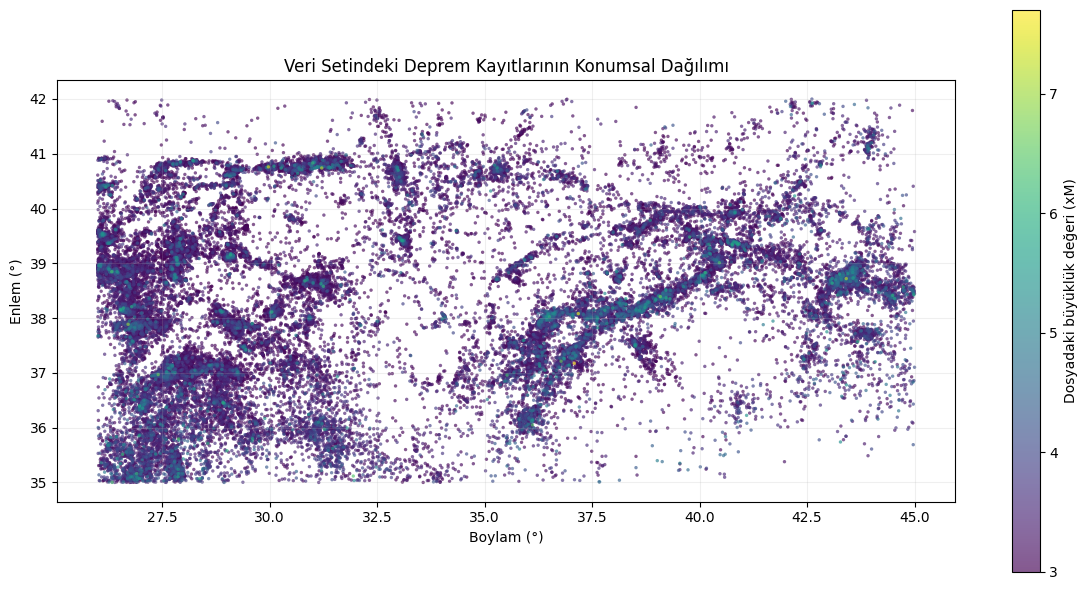

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Büyük değerlerin noktaları üstte görünsün.
konum_verisi = deprem.sort_values("buyukluk")

fig, ax = plt.subplots(figsize=(12, 6))

noktalar = ax.scatter(
    konum_verisi["boylam"],
    konum_verisi["enlem"],
    c=konum_verisi["buyukluk"],
    cmap="viridis",
    s=6,
    alpha=0.65,
    linewidths=0
)

ax.set_title("Veri Setindeki Deprem Kayıtlarının Konumsal Dağılımı")
ax.set_xlabel("Boylam (°)")
ax.set_ylabel("Enlem (°)")

# Enlem-boylam gösterimindeki görsel bozulmayı yaklaşık azalt.
ortalama_enlem = konum_verisi["enlem"].mean()
ax.set_aspect(1 / np.cos(np.radians(ortalama_enlem)))

ax.grid(alpha=0.2)
fig.colorbar(noktalar, ax=ax, label="Dosyadaki büyüklük değeri (xM)")

plt.tight_layout()
plt.show()

### Bulgular ve Yorum

Kayıtların coğrafi olarak eşit dağılmadığı görülmektedir.
Batı kesiminde, yaklaşık 26–30° boylamları arasında yoğun bir
dağılım vardır. Ayrıca bazı alanlarda kayıtların şerit benzeri
yapılar boyunca sıralandığı gözlenmektedir.

Noktaların çoğu renk ölçeğinin düşük büyüklük tarafındadır.
Bununla birlikte noktaların üst üste binmesi nedeniyle büyüklüklerin
sayısal dağılımı yalnızca bu grafikten kesin olarak belirlenemez.
Bu dağılım ayrıca histogram ile incelenecektir.

Grafikte fay hattı verisi kullanılmadığından görülen yapılar kesin
olarak belirli faylarla eşleştirilmemiştir. Kayıt yoğunluğu doğrudan
gelecekteki deprem olasılığı veya risk düzeyi olarak yorumlanmamıştır.

## 4. Veri Keşfi: Büyüklük Dağılımı

### Amaç ve Yöntem
Dosyadaki xM büyüklük değerlerinin dağılımını incelemek için
histogram kullanılmıştır. Histogram, değerleri aralıklara ayırarak
her aralıkta kaç kayıt bulunduğunu gösterir.

Yatay eksen büyüklüğü, dikey eksen kayıt sayısını göstermektedir.
Bu inceleme yalnızca mevcut veri setini temsil eder; dosyada
3,0'dan küçük xM değeri bulunmaması, bu büyüklükte depremlerin
gerçekleşmediği anlamına gelmez.

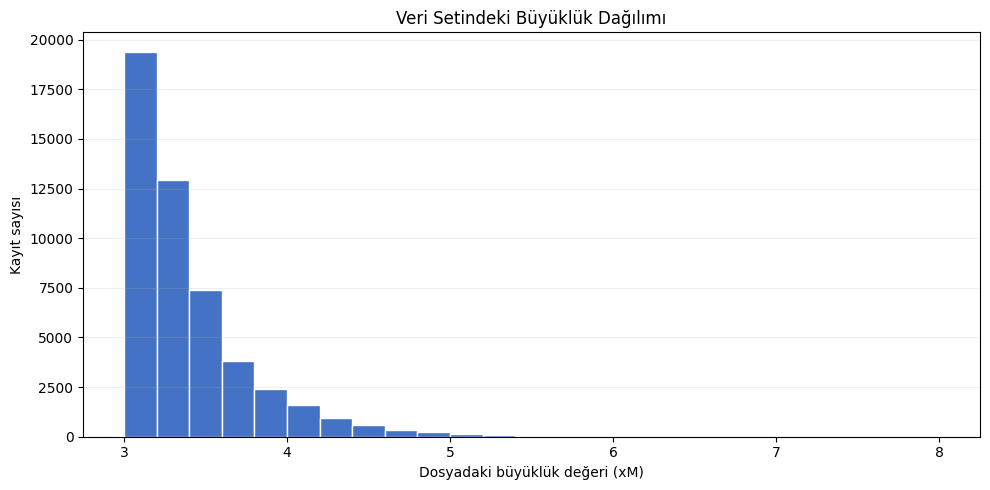

Ortalama büyüklük: 3.34
Medyan büyüklük: 3.20
En küçük değer: 3.0
En büyük değer: 7.7
xM değeri 5 ve üzerinde olan kayıtların oranı: %0.69


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

# 0,2 genişliğinde büyüklük aralıkları oluştur.
alt = np.floor(deprem["buyukluk"].min() * 5) / 5
ust = np.ceil(deprem["buyukluk"].max() * 5) / 5
sinirlar = np.round(np.arange(alt, ust + 0.21, 0.2), 2)

ax.hist(
    deprem["buyukluk"],
    bins=sinirlar,
    color="#4472C4",
    edgecolor="white"
)

ax.set_title("Veri Setindeki Büyüklük Dağılımı")
ax.set_xlabel("Dosyadaki büyüklük değeri (xM)")
ax.set_ylabel("Kayıt sayısı")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Ortalama büyüklük: {deprem['buyukluk'].mean():.2f}")
print(f"Medyan büyüklük: {deprem['buyukluk'].median():.2f}")
print(f"En küçük değer: {deprem['buyukluk'].min():.1f}")
print(f"En büyük değer: {deprem['buyukluk'].max():.1f}")

oran = deprem["buyukluk"].ge(5).mean() * 100
print(f"xM değeri 5 ve üzerinde olan kayıtların oranı: %{oran:.2f}")

### Bulgular ve Yorum

Dosyadaki xM büyüklük değerleri 3,0 ile 7,7 arasındadır.
Ortalama 3,34, medyan ise 3,20 olarak hesaplanmıştır.
Kayıtların çoğu düşük büyüklük aralıklarında yoğunlaşmakta,
yüksek değerlere doğru kayıt sayısı azalmaktadır.
Dağılım sağa çarpık bir yapı göstermektedir.

xM değeri 5 ve üzerinde olan kayıtlar toplamın yaklaşık
%0,69'unu oluşturmaktadır. Bu oran yalnızca incelenen veri
setini tanımlar; gelecekte büyük bir deprem gerçekleşme
olasılığı olarak yorumlanamaz.

Yüksek büyüklük değerleri, yalnızca az sayıda oldukları için
hatalı veri kabul edilmemiş ve silinmemiştir.

## 5. Veri Keşfi: Derinlik Dağılımı

### Amaç ve Yöntem

Kayıtların derinlik dağılımı histogram ile incelenmiştir.
Yatay eksen kilometre cinsinden derinliği, dikey eksen
ilgili aralıktaki kayıt sayısını göstermektedir.

Sıfır derinlikli kayıtlar bu keşif aşamasında korunmuştur.
Bu değerlerin anlamı kesinleştirilmediğinden, tamamının
gerçek yüzey derinliğini temsil ettiği varsayılmamıştır.

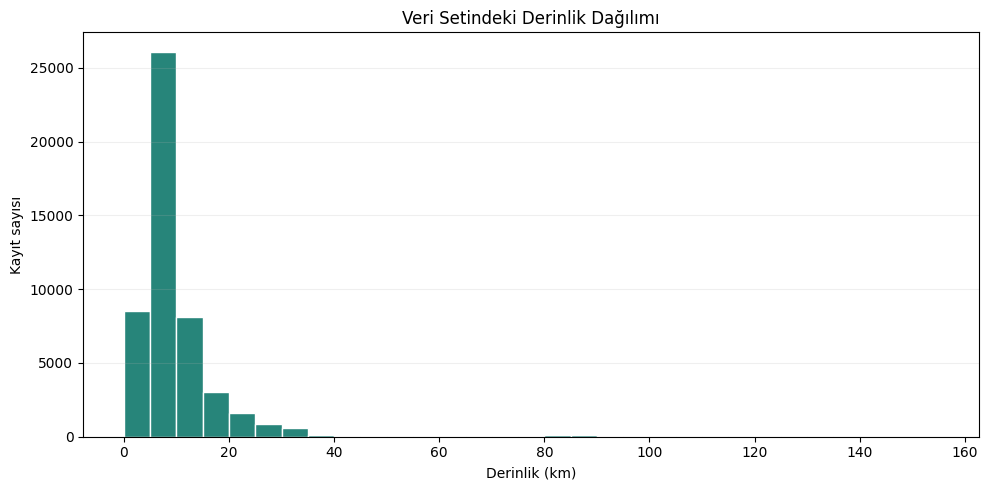

Ortalama derinlik: 10.00 km
Medyan derinlik: 6.90 km
En büyük derinlik: 154.70 km
Sıfır derinlikli kayıt sayısı: 1756
Sıfır derinlikli kayıt oranı: %3.51
0'dan büyük, 5 km'den küçük derinlikli kayıt: 6749


In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

# Derinlikleri 5 km genişliğinde aralıklara ayır.
en_derin = deprem["derinlik_km"].max()
sinirlar = np.arange(0, en_derin + 5, 5)

ax.hist(
    deprem["derinlik_km"],
    bins=sinirlar,
    color="#27857A",
    edgecolor="white"
)

ax.set_title("Veri Setindeki Derinlik Dağılımı")
ax.set_xlabel("Derinlik (km)")
ax.set_ylabel("Kayıt sayısı")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Ortalama derinlik: {deprem['derinlik_km'].mean():.2f} km")
print(f"Medyan derinlik: {deprem['derinlik_km'].median():.2f} km")
print(f"En büyük derinlik: {en_derin:.2f} km")

sifir_sayisi = deprem["derinlik_km"].eq(0).sum()
print(f"Sıfır derinlikli kayıt sayısı: {sifir_sayisi}")
print(f"Sıfır derinlikli kayıt oranı: %{100 * sifir_sayisi / len(deprem):.2f}")

# İlk histogram sütununda sıfırlar ve 0–5 km arası
# pozitif değerler birlikte bulunur.
print(
    "0'dan büyük, 5 km'den küçük derinlikli kayıt:",
    ((deprem["derinlik_km"] > 0) &
     (deprem["derinlik_km"] < 5)).sum()
)

### Bulgular ve Yorum

Derinlikler özellikle 5–10 km aralığında yoğunlaşmaktadır.
Ortalama derinlik 10,00 km, medyan derinlik 6,90 km ve
en yüksek derinlik 154,70 km olarak bulunmuştur.
Dağılım sağa çarpıktır; yüksek derinlikli kayıtların sayısı
düşük derinlikli kayıtlara göre daha azdır.

1.756 kayıtta derinlik sıfırdır ve bu kayıtlar toplamın
yaklaşık %3,51'ini oluşturmaktadır. Ayrıca 6.749 kayıtta
derinlik sıfırdan büyük, 5 km'den küçüktür.
Histogramın ilk sütunu bu iki grubu birlikte içermektedir.

Yüksek derinlikler yalnızca dağılımın uç kısmında yer aldıkları
için hatalı kabul edilmemiştir. Sıfır derinlikli kayıtların
model sonuçlarına etkisi ayrıca değerlendirilecektir.

### Derinlik ve Büyüklük İçin Aykırı Değer İncelemesi

Derinlik ve büyüklük alanlarında dağılımın uçlarında kalan
kayıtları belirlemek için IQR yöntemi kullanılmıştır.

IQR, üçüncü çeyrek (Q3) ile birinci çeyrek (Q1) arasındaki
farktır. Q1 − 1,5 × IQR altındaki ve Q3 + 1,5 × IQR
üstündeki değerler inceleme adayı olarak işaretlenmiştir.

Bu sınırlar veri hatasını veya fiziksel olarak olanaksız
değerleri tanımlamaz. Sağa çarpık dağılımlarda geçerli
gözlemler de sınırların dışında kalabilir.

İnceleme özgün derinlik ve xM değerleri üzerinde yapılmıştır.
İşaretlenen kayıtlar otomatik olarak silinmemiştir.
Sıfır derinliklerin anlamı ise ayrı bir veri kalitesi konusu
olarak ele alınmıştır; IQR kontrolü bu belirsizliği çözmez.

,Q1,Q3,IQR,alt_sinir,ust_sinir,altinda_kayit,ustunde_kayit,aday_orani_yuzde
ozellik,,,,,,,,
derinlik_km,5.0,10.5,5.5,-3.25,18.75,0,4735,9.470
buyukluk,3.1,3.5,0.4,2.50,4.10,0,2441,4.882


En az bir alanda IQR adayı: 6894
Her iki alanda IQR adayı: 282
Bu işlemde silinen kayıt: 0


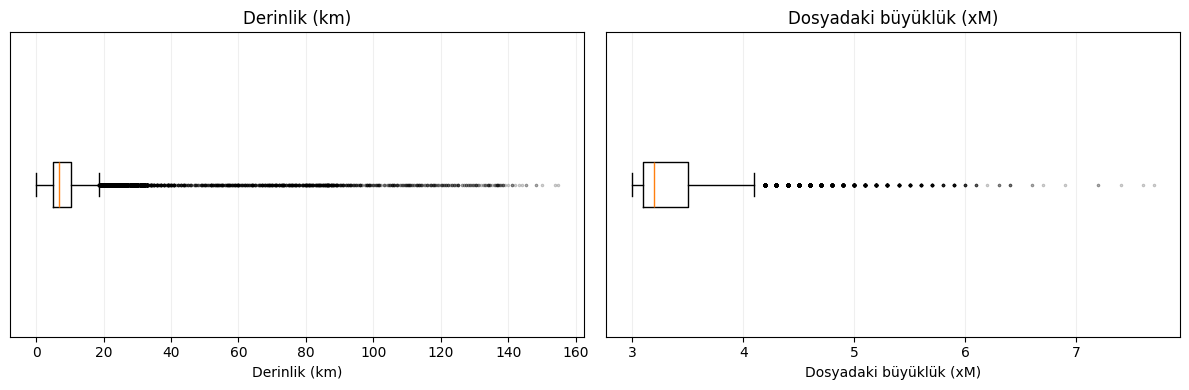


En yüksek derinliğe sahip 5 kayıt:


,deprem_kodu,derinlik_km,buyukluk,yer
6704,20201001110537,154.7,4.9,AKDENIZ
14346,20131205214415,154.0,3.0,AKDENIZ
24926,20081116164328,150.0,3.3,ONIKI ADALAR (AKDENIZ)
9681,20180407090319,148.3,3.1,AKDENIZ
13238,20150208182040,148.3,3.1,SALUR-MANAVGAT (ANTALYA) [ 1.87 km]



En yüksek büyüklüğe sahip 5 kayıt:


,deprem_kodu,derinlik_km,buyukluk,yer
3765,20230206011732,5.5,7.7,YAMACOBA-SEHITKAMIL (GAZIANTEP) [North West 0...
3502,20230206102447,5.0,7.6,EKINOZU (KAHRAMANMARAS) [North West 2.7 km]
44749,19990817000137,18.0,7.4,BASISKELE (KOCAELI) [North East 2.0 km]
18684,20111023104121,5.0,7.2,YEMLICE- (VAN) [North West 1.5 km]
44180,19991112165720,25.0,7.2,UGUR- (DUZCE) [North East 0.3 km]


In [8]:
# Ana çalışma tablosunu değiştirmeden inceleme yap.
aykiri_inceleme = deprem.copy()
iqr_sonuclari = []

for sutun in ["derinlik_km", "buyukluk"]:
    degerler = aykiri_inceleme[sutun]

    q1 = degerler.quantile(0.25)
    q3 = degerler.quantile(0.75)
    iqr = q3 - q1

    alt_sinir = q1 - 1.5 * iqr
    ust_sinir = q3 + 1.5 * iqr

    altinda = degerler.lt(alt_sinir)
    ustunde = degerler.gt(ust_sinir)
    aday = altinda | ustunde

    aykiri_inceleme[f"{sutun}_iqr_adayi"] = aday

    iqr_sonuclari.append({
        "ozellik": sutun,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "alt_sinir": alt_sinir,
        "ust_sinir": ust_sinir,
        "altinda_kayit": int(altinda.sum()),
        "ustunde_kayit": int(ustunde.sum()),
        "aday_orani_yuzde": aday.mean() * 100
    })

iqr_ozet = pd.DataFrame(iqr_sonuclari).set_index("ozellik")
display(iqr_ozet.round(3))

# İki alandan en az birinde işaretlenen kayıtları say.
aday_sutunlari = [
    "derinlik_km_iqr_adayi",
    "buyukluk_iqr_adayi"
]

herhangi_biri = aykiri_inceleme[aday_sutunlari].any(axis=1)
ikisi_birden = aykiri_inceleme[aday_sutunlari].all(axis=1)

print("En az bir alanda IQR adayı:", herhangi_biri.sum())
print("Her iki alanda IQR adayı:", ikisi_birden.sum())
print("Bu işlemde silinen kayıt: 0")

# Kutu grafikleri: kutu Q1–Q3 aralığını, ortadaki çizgi
# medyanı, bıyık dışındaki noktalar uç gözlemleri gösterir.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, sutun, baslik in zip(
    axes,
    ["derinlik_km", "buyukluk"],
    ["Derinlik (km)", "Dosyadaki büyüklük (xM)"]
):
    ax.boxplot(
        aykiri_inceleme[sutun].dropna(),
        vert=False,
        whis=1.5,
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.25
        }
    )
    ax.set_title(baslik)
    ax.set_xlabel(baslik)
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nEn yüksek derinliğe sahip 5 kayıt:")
display(
    aykiri_inceleme.nlargest(5, "derinlik_km")[
        ["deprem_kodu", "derinlik_km", "buyukluk", "yer"]
    ]
)

print("\nEn yüksek büyüklüğe sahip 5 kayıt:")
display(
    aykiri_inceleme.nlargest(5, "buyukluk")[
        ["deprem_kodu", "derinlik_km", "buyukluk", "yer"]
    ]
)

### Aykırı Değer İncelemesinin Bulguları

IQR yöntemiyle derinlik için alt sınır −3,25 km, üst sınır
18,75 km olarak hesaplanmıştır. Üst sınırın üzerinde
4.735 kayıt (%9,47) bulunmaktadır.

Dosyadaki xM büyüklüğü için alt sınır 2,50, üst sınır 4,10
olarak hesaplanmıştır. Üst sınırın üzerinde 2.441 kayıt
(%4,882) bulunmaktadır. Her iki özellikte de alt sınırın
altında kayıt yoktur.

En az bir özellikte sınır dışında kalan 6.894 kayıt
(%13,788), her iki özellikte sınır dışında kalan 282 kayıt
vardır. Kutu grafikleri, iki dağılımın da yüksek değerlere
doğru uzayan kuyruklarını göstermektedir.

En yüksek derinlikli kayıtlar 148,3–154,7 km, en yüksek
büyüklüklü kayıtlar ise 7,2–7,7 aralığındadır. Bunlar
dosyadaki değerlerdir; bu inceleme tek başına ölçümlerin
doğruluğunu doğrulamaz.

IQR sınırları istatistiksel eşiklerdir; fiziksel sınırlar
veya veri hatası ölçütleri değildir. Nadir ve yüksek
büyüklüklü kayıtları yalnızca bu nedenle silmek, incelenen
kataloğun kapsamını değiştirecektir. Bu nedenle hiçbir
kayıt otomatik olarak silinmemiş veya sınır değerlere
çekilmemiştir.

Sıfır derinlikler IQR sınırları içinde kalmıştır. Ancak bu,
değerlerin geçerli olduğunu kanıtlamaz. Sıfır derinlikler
ayrı bir veri kalitesi konusu olarak değerlendirilmiş ve
etkileri duyarlılık analiziyle incelenmiştir.

Derinliğe uygulanan log1p dönüşümü yüksek değerler
arasındaki farkları azaltır; uç gözlemleri ortadan
kaldırmaz. StandardScaler da aykırı değerlere karşı
dayanıklı bir ölçekleyici değildir. Uç kayıtların
K-Means merkezleri üzerindeki etkisi tamamen giderilmiş
sayılmamalıdır.

## 6. Veri Keşfi: Yıllara Göre Kayıt Sayısı

### Amaç ve Yöntem

Kayıtlar oluş tarihlerinin yılına göre gruplanmış ve her yılın
kayıt sayısı sütun grafiğiyle gösterilmiştir.

Veri seti 11 Eylül 1994–31 Temmuz 2023 dönemini kapsamaktadır.
Bu nedenle 1994 ve 2023 kısmi yıllardır ve grafikte farklı
renkle belirtilmiştir.

Yıllık sayılar yalnızca bu dosyadaki kayıtları temsil eder.
Değişimler tek başına deprem riskindeki artış veya azalış
olarak yorumlanamaz.

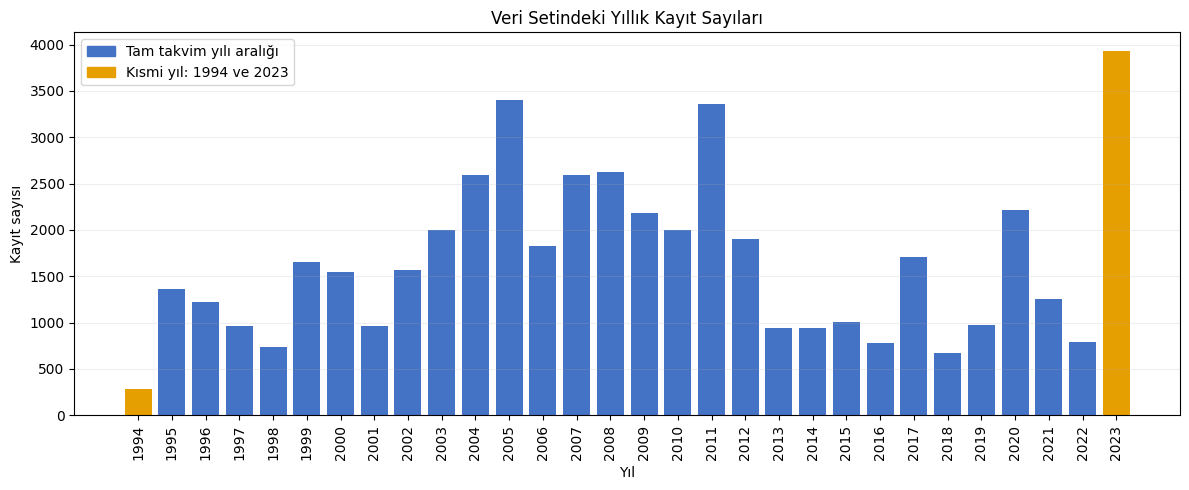

En fazla kayıt bulunan 5 yıl:
tarih
2023    3936
2005    3403
2011    3364
2008    2625
2007    2598

Not: 2023 yalnızca 31 Temmuz'a kadar olan dönemi kapsar.


In [9]:
from matplotlib.patches import Patch

# Kayıtları yıllara göre say.
yillik = (
    deprem.groupby(deprem["tarih"].dt.year)
    .size()
    .sort_index()
)

# Kısmi yılları turuncu, diğer yılları mavi göster.
renkler = [
    "#E69F00" if yil in [1994, 2023] else "#4472C4"
    for yil in yillik.index
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(yillik.index, yillik.values, color=renkler)

ax.set_title("Veri Setindeki Yıllık Kayıt Sayıları")
ax.set_xlabel("Yıl")
ax.set_ylabel("Kayıt sayısı")
ax.set_xticks(yillik.index)
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.2)

ax.legend(handles=[
    Patch(color="#4472C4", label="Tam takvim yılı aralığı"),
    Patch(color="#E69F00", label="Kısmi yıl: 1994 ve 2023")
])

plt.tight_layout()
plt.show()

print("En fazla kayıt bulunan 5 yıl:")
print(yillik.sort_values(ascending=False).head(5).to_string())
print("\nNot: 2023 yalnızca 31 Temmuz'a kadar olan dönemi kapsar.")

### Bulgular ve Yorum

Veri setinde en fazla kayıt bulunan yıl, 3.936 kayıtla 2023'tür.
Bunu 2005 (3.403), 2011 (3.364), 2008 (2.625) ve
2007 (2.598) izlemektedir.

2023 yalnızca 31 Temmuz'a kadar olan dönemi, 1994 ise
11 Eylül'den sonraki dönemi kapsamaktadır. Bu nedenle bu
yıllar diğer yıllarla eşit gözlem süresine sahip değildir.

Yıllık kayıt sayıları dalgalanmaktadır. Bu grafik tek başına
dalgalanmaların nedenini veya gelecekteki deprem riskini
belirlemek için yeterli değildir.

## 7. Model Öncesi Hazırlık: Özellikler ve Dönüşüm

### Kullanılacak Özellikler
Kümeleme için enlem, boylam, derinlik ve dosyadaki xM
büyüklük değeri kullanılacaktır. Tarih, yer, kayıt türü ve
deprem kodu yorumlama ve takip amacıyla korunacak, modele
girdi olarak verilmeyecektir.

### Derinlik Dönüşümü
Derinlik dağılımı sağa çarpık olduğundan log(1 + derinlik)
dönüşümü uygulanacaktır. Bu dönüşüm büyük derinlik değerleri
arasındaki sayısal farkları sıkıştırır; kayıt silmez ve
dağılımın normal olacağını garanti etmez.

### Veriyle İlgili Kararlar
İlk modelde sıfır derinlikli kayıtlar korunacaktır.
Bu kayıtların etkisi daha sonra duyarlılık analiziyle
incelenecektir. Kayıt türlerinin anlamı doğrulanamadığından
bu aşamada tür filtresi uygulanmamıştır.

xM, dosyada sunulan büyüklük alanı olarak kullanılmaktadır;
tek ve homojen bir Mw ölçeği olduğu varsayılmamaktadır.

In [10]:
# Çalışma tablosunun ayrı bir kopyasını oluştur.
model_verisi = deprem.copy()

# Kullanılacak sayısal alanları kontrol et.
sayisal_sutunlar = [
    "enlem", "boylam", "derinlik_km", "buyukluk"
]

assert np.isfinite(
    model_verisi[sayisal_sutunlar].to_numpy()
).all(), "Sayısal alanlarda eksik veya sonsuz değer var."

assert model_verisi["derinlik_km"].ge(0).all(), \
    "Negatif derinlik var; dönüşümden önce incelenmeli."

# Orijinal derinliği koruyup dönüştürülmüş sütun ekle.
model_verisi["derinlik_log"] = np.log1p(
    model_verisi["derinlik_km"]
)

ozellikler = ["enlem", "boylam", "derinlik_log", "buyukluk"]
X_ham = model_verisi[ozellikler].copy()

print("Modele hazırlanacak kayıt sayısı:", len(X_ham))
print("Özellikler:", ozellikler)

print("\nDerinlik dönüşümünden örnekler:")
print(
    model_verisi[["derinlik_km", "derinlik_log"]]
    .head()
    .round(3)
    .to_string(index=False)
)

Modele hazırlanacak kayıt sayısı: 50000
Özellikler: ['enlem', 'boylam', 'derinlik_log', 'buyukluk']

Derinlik dönüşümünden örnekler:
 derinlik_km  derinlik_log
         4.0         1.609
         5.2         1.825
         6.2         1.974
         5.3         1.841
         2.4         1.224


## 8. Özelliklerin Standartlaştırılması

### Amaç
K-Means, kayıtları özellik uzayındaki uzaklıklarına göre kümeler.
Enlem, boylam, logaritmik derinlik ve büyüklük farklı ölçeklere
sahiptir. Ölçekleme yapılmazsa, sayısal değişkenliği daha yüksek
olan özellikler uzaklık hesabında daha fazla etkili olabilir.

### Kullanılan Yöntem
StandardScaler ile her özellikten kendi ortalaması çıkarılır
ve sonuç kendi standart sapmasına bölünür:

z = (değer − ortalama) / standart sapma

Bu işlem sonunda her özelliğin ortalaması yaklaşık 0,
standart sapması yaklaşık 1 olur.

### Yorumlama
- Negatif standartlaştırılmış değer, ilgili özelliğin ortalamasının
  altında kalındığını gösterir; fiziksel olarak negatif derinlik
  veya büyüklük anlamına gelmez.
- Standartlaştırma, değerleri 0–1 aralığına sıkıştırmaz ve
  dağılımı normal dağılıma dönüştürmez.
- Özellikleri benzer ölçeğe getirir; bilimsel açıdan aynı öneme
  sahip olduklarını kanıtlamaz.

### Yöntemin Sınırı
Standartlaştırılmış enlem ve boylamla hesaplanan uzaklık,
kilometre cinsinden coğrafi uzaklık değildir. Oluşacak kümeler,
seçilen dört özellik bakımından benzer kayıt grupları olarak
yorumlanacaktır; kesin coğrafi sınırlar veya risk bölgeleri
olarak değerlendirilmeyecektir.

Bu çalışma mevcut kayıtları betimlemeyi amaçladığından,
ölçekleyici çalışma verisinin tamamına uygulanmaktadır.

In [11]:
from sklearn.preprocessing import StandardScaler

# Her özelliğin ortalamasını ve standart sapmasını öğren,
# ardından aynı veriyi bu değerlerle standartlaştır.
olcekleyici = StandardScaler()
X_olcekli = olcekleyici.fit_transform(X_ham)

# Sütun isimlerini koruyarak kontrol tablosu oluştur.
X_olcekli_df = pd.DataFrame(
    X_olcekli,
    columns=ozellikler,
    index=X_ham.index
)

# StandardScaler, standart sapmayı ddof=0 ile hesaplar.
olcek_kontrol = pd.DataFrame({
    "ortalama": X_olcekli_df.mean(),
    "standart_sapma": X_olcekli_df.std(ddof=0)
})

print("Ölçeklenmiş veri boyutu:", X_olcekli.shape)

print("\nÖlçekleme kontrolü:")
display(olcek_kontrol.round(6))

print("\nÖlçeklenmiş ilk 5 kayıt:")
display(X_olcekli_df.head().round(3))

Ölçeklenmiş veri boyutu: (50000, 4)

Ölçekleme kontrolü:


,ortalama,standart_sapma
enlem,-0.0,1.0
boylam,0.0,1.0
derinlik_log,0.0,1.0
buyukluk,-0.0,1.0



Ölçeklenmiş ilk 5 kayıt:


,enlem,boylam,derinlik_log,buyukluk
0,-0.604,0.732,-0.666,0.392
1,-0.109,0.952,-0.375,0.392
2,-0.318,-1.066,-0.172,-0.871
3,1.713,-0.339,-0.353,-0.618
4,-0.117,0.909,-1.190,-0.871


## 9. K-Means ile Küme Sayısının Değerlendirilmesi

### Neden Denetimsiz Öğrenme?
Verimizde her depremin hangi gruba ait olduğunu gösteren hazır
küme etiketleri bulunmamaktadır. Amaç, seçilen özelliklerdeki
benzerliklerden hareketle kayıtları gruplamaktır.
Bu nedenle denetimsiz öğrenme kullanılmaktadır.

### Neden K-Means?
K-Means, yorumlanabilir bir başlangıç modeli sunar. Her kaydı
en yakın küme merkezine atar ve küme içindeki kareli uzaklıkların
toplamını azaltmaya çalışır.

Yöntem, benzer büyüklükte ve kompakt kümelerde daha iyi çalışır.
Uzamış veya düzensiz şekilli grupları ayırmakta zorlanabilir.
Bu nedenle bulunan kümeler, gerçek fayların veya doğal
deprem bölgelerinin kesin karşılığı olarak yorumlanmayacaktır.

### Küme Sayısı Nasıl Değerlendirilecek?
2–10 arasındaki küme sayıları üç ölçütle karşılaştırılacaktır:

- Inertia: Kayıtların kendi küme merkezlerine olan kareli
  uzaklıklarının toplamıdır. Küme sayısı arttıkça azalır.
  Elbow grafiğinde azalmanın belirgin biçimde yavaşladığı
  bir nokta olup olmadığı incelenir.
- Silhouette skoru: Kayıtların kendi kümelerine ne kadar yakın,
  diğer kümelerden ne kadar ayrı olduğunu değerlendirir.
  −1 ile 1 arasındadır; daha yüksek değer tercih edilir.
- Davies–Bouldin indeksi: Küme içi yayılımı ve kümeler arasındaki
  ayrımı birlikte değerlendirir. Daha düşük değer tercih edilir.

Bu değerler doğruluk yüzdesi değildir. Küme sayısı, metrikler
ve kümelerin yorumlanabilirliği birlikte değerlendirilerek seçilecektir.
En iyi sonuç yalnızca denenen aralık ve kullanılan özellikler
için geçerlidir.

### Deney Düzeni
Her model 50.000 kaydın tamamıyla oluşturulacaktır.
Silhouette hesabının maliyetini azaltmak için tüm modellerde
aynı, rastgele seçilmiş 3.000 kayıt kullanılacaktır.
Diğer iki ölçüt tüm kayıtlar üzerinden hesaplanacaktır.

Her küme sayısı için 20 farklı başlangıç denenerek en düşük
inertia değerine sahip çözüm kullanılacaktır. Tekrarlanabilirlik
için rastgelelik tohumu 42 olarak sabitlenecektir.

K=2 tamamlandı | Silhouette: 0.2535 | Davies–Bouldin: 1.6081
K=3 tamamlandı | Silhouette: 0.2548 | Davies–Bouldin: 1.3802
K=4 tamamlandı | Silhouette: 0.2672 | Davies–Bouldin: 1.2050
K=5 tamamlandı | Silhouette: 0.2874 | Davies–Bouldin: 1.1002
K=6 tamamlandı | Silhouette: 0.2748 | Davies–Bouldin: 1.1166
K=7 tamamlandı | Silhouette: 0.2672 | Davies–Bouldin: 1.2001
K=8 tamamlandı | Silhouette: 0.2500 | Davies–Bouldin: 1.2283
K=9 tamamlandı | Silhouette: 0.2278 | Davies–Bouldin: 1.2699
K=10 tamamlandı | Silhouette: 0.2323 | Davies–Bouldin: 1.2027

Küme sayısı karşılaştırması:


,k,inertia,silhouette,davies_bouldin
0,2,152651.1814,0.2535,1.6081
1,3,123531.2745,0.2548,1.3802
2,4,101884.4209,0.2672,1.2050
3,5,87808.5410,0.2874,1.1002
4,6,78467.3787,0.2748,1.1166
5,7,72866.8146,0.2672,1.2001
6,8,67542.0083,0.2500,1.2283
7,9,63288.2075,0.2278,1.2699
8,10,59526.5423,0.2323,1.2027


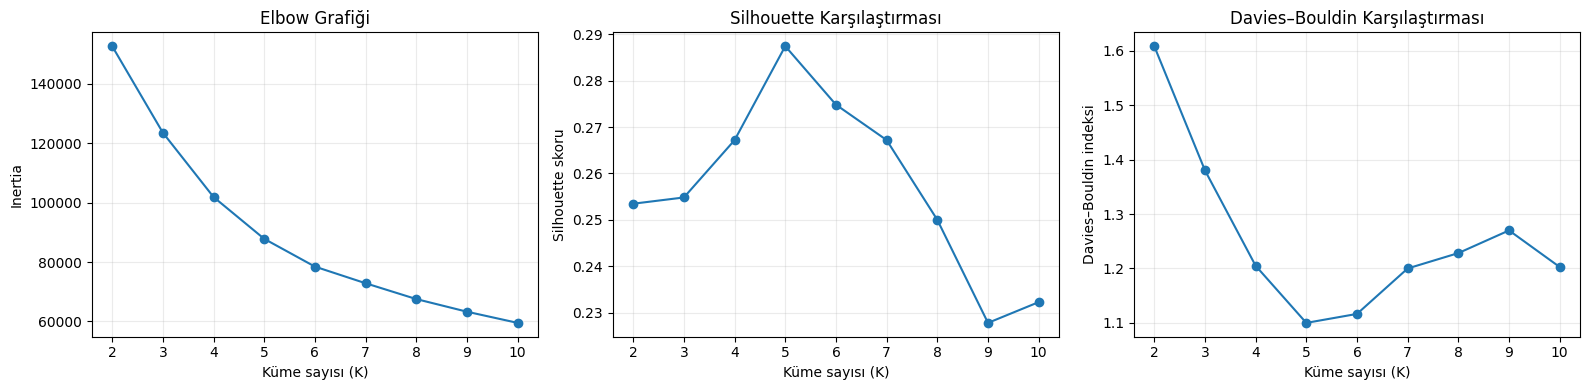

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Bütün küme sayılarında aynı kayıtlarla Silhouette hesapla.
rng = np.random.default_rng(42)
ornek_indeksleri = rng.choice(
    len(X_olcekli),
    size=min(3000, len(X_olcekli)),
    replace=False
)
X_ornek = X_olcekli[ornek_indeksleri]

sonuclar = []
k_modelleri = {}

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    # Modeli tüm kayıtlarla oluştur ve küme etiketlerini al.
    etiketler = model.fit_predict(X_olcekli)
    ornek_etiketler = etiketler[ornek_indeksleri]

    # Silhouette için örneklemde en az iki küme bulunmalıdır.
    if 2 <= len(np.unique(ornek_etiketler)) < len(X_ornek):
        sil = silhouette_score(X_ornek, ornek_etiketler)
    else:
        sil = np.nan

    db = davies_bouldin_score(X_olcekli, etiketler)

    sonuclar.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": sil,
        "davies_bouldin": db
    })

    # Seçim sonrasında modeli yeniden eğitmeden kullanabiliriz.
    k_modelleri[k] = model

    print(
        f"K={k} tamamlandı | "
        f"Silhouette: {sil:.4f} | "
        f"Davies–Bouldin: {db:.4f}"
    )

k_sonuclari = pd.DataFrame(sonuclar)

print("\nKüme sayısı karşılaştırması:")
display(k_sonuclari.round(4))

# Üç ölçütü yan yana göster.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

grafikler = [
    ("inertia", "Elbow Grafiği", "Inertia"),
    ("silhouette", "Silhouette Karşılaştırması", "Silhouette skoru"),
    ("davies_bouldin", "Davies–Bouldin Karşılaştırması",
     "Davies–Bouldin indeksi")
]

for ax, (sutun, baslik, y_etiketi) in zip(axes, grafikler):
    ax.plot(k_sonuclari["k"], k_sonuclari[sutun], marker="o")
    ax.set_title(baslik)
    ax.set_xlabel("Küme sayısı (K)")
    ax.set_ylabel(y_etiketi)
    ax.set_xticks(k_sonuclari["k"])
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Bulgular ve Küme Sayısı Seçimi

2–10 arasındaki küme sayıları karşılaştırıldığında, en yüksek
Silhouette skoru (0,2874) ve en düşük Davies–Bouldin indeksi
(1,1002) K=5 için elde edilmiştir.

Inertia, küme sayısı arttıkça beklenildiği gibi azalmıştır.
Elbow grafiğinde keskin bir kırılma bulunmamakla birlikte,
ek küme eklemenin sağladığı azalma giderek küçülmektedir.

İki içsel değerlendirme ölçütünün aynı seçeneği desteklemesi
nedeniyle analizde K=5 ile devam edilmiştir. Bununla birlikte,
Silhouette skorunun 1'e yakın olmaması, kümelerin güçlü ve
tamamen ayrışmış gruplar olarak yorumlanmaması gerektiğini
göstermektedir.

Bu seçim kullanılan özellikler, ön işleme adımları ve denenen
küme sayıları için geçerlidir. Küme profilleri ve duyarlılık
analizleriyle ayrıca değerlendirilecektir.

## 10. Seçilen Model ve Küme Profilleri

Önceki aşamada oluşturulan K=5 modeli kullanılarak her kaydın
küme etiketi çalışma tablosuna eklenmiştir.

Kümeler; kayıt sayısı, veri içindeki payı, ortalama konumu,
derinlik ve büyüklük istatistikleri bakımından karşılaştırılacaktır.
Yorumların anlaşılır olması için derinlik kilometre cinsinden,
büyüklük ise dosyadaki özgün xM değerleriyle özetlenecektir.

Ortalama ile birlikte medyan da raporlanacaktır. Böylece az
sayıdaki yüksek değerin ortalama üzerindeki etkisi görülebilecektir.

Küme numaraları yalnızca grup kimliğidir. Daha büyük bir küme
numarası, daha yüksek tehlike veya risk anlamına gelmez.

In [13]:
# Önceden oluşturduğumuz K=5 modelini kullan.
secilen_k = 5
son_model = k_modelleri[secilen_k]

# Model etiketleri 0–4; gösterim kolaylığı için 1–5 yapıyoruz.
model_verisi["kume"] = son_model.labels_ + 1

# İstatistikleri özgün birimler üzerinden hesapla.
kume_profilleri = (
    model_verisi.groupby("kume")
    .agg(
        kayit_sayisi=("deprem_kodu", "size"),
        enlem_ort=("enlem", "mean"),
        boylam_ort=("boylam", "mean"),
        derinlik_ort_km=("derinlik_km", "mean"),
        derinlik_medyan_km=("derinlik_km", "median"),
        buyukluk_ort=("buyukluk", "mean"),
        buyukluk_medyan=("buyukluk", "median"),
        buyukluk_maks=("buyukluk", "max"),
        sifir_derinlik_yuzde=(
            "sifir_derinlik",
            lambda s: s.mean() * 100
        )
    )
)

kume_profilleri.insert(
    1,
    "pay_yuzde",
    kume_profilleri["kayit_sayisi"] / len(model_verisi) * 100
)

print("Küme profilleri:")
display(kume_profilleri.round(3))

print(
    "\nKümelerdeki toplam kayıt:",
    kume_profilleri["kayit_sayisi"].sum()
)

Küme profilleri:


,kayit_sayisi,pay_yuzde,enlem_ort,boylam_ort,derinlik_ort_km,derinlik_medyan_km,buyukluk_ort,buyukluk_medyan,buyukluk_maks,sifir_derinlik_yuzde
kume,,,,,,,,,,
1,3485,6.970,38.326,31.142,0.851,1.0,3.279,3.2,4.3,49.555
2,15250,30.500,39.339,29.174,8.289,7.0,3.199,3.1,4.0,0.000
3,4590,9.180,38.149,34.485,9.818,6.3,4.283,4.2,7.7,0.632
4,12371,24.742,36.587,29.285,17.632,10.7,3.299,3.2,4.3,0.000
5,14304,28.608,38.717,40.141,7.496,5.3,3.256,3.2,4.0,0.000



Kümelerdeki toplam kayıt: 50000


### Küme Profillerinin Yorumu

K-Means sonucunda 50.000 kayıt beş kümeye ayrılmıştır.
En büyük küme, kayıtların %30,50'sini içeren Küme 2;
en küçük küme ise %6,97 ile Küme 1 olmuştur.

Küme 1, 0,851 km ortalama derinlik ve %49,555 sıfır
derinlik oranıyla ayrışmaktadır. Sıfır değerlerinin anlamı
doğrulanamadığından, bu grubun oluşumunda veri kayıt
özelliklerinin etkili olabileceği değerlendirilmiştir.
Bu durum, sıfır derinlikli kayıtlar dışlanarak yapılacak
duyarlılık analizinde incelenecektir.

Küme 3, 4,283 ortalama ve 4,2 medyan büyüklükle diğer
kümelerden ayrılmaktadır. Bu özellik, geçmiş kayıtlardaki
büyüklük dağılımını tanımlar; gelecekteki deprem riskini göstermez.

Küme 4, 17,632 km ortalama ve 10,7 km medyan derinlikle
kümeler arasında en yüksek derinlik değerlerine sahiptir.
Ortalamanın medyandan yüksek olması, daha yüksek derinlikli
kayıtların ortalamayı yukarı çektiğini göstermektedir.

Küme 2 ve Küme 5'in ortalama büyüklükleri birbirine yakınken,
ortalama konumları belirgin biçimde farklıdır. Konumsal
ayrımın görünümü bir sonraki grafikte incelenecektir.

Bu profiller, kullanılan dört özellik üzerinden oluşturulmuştur.
Küme numaraları bir tehlike sıralaması değildir.

## 11. Kümelerin Konumsal Dağılımı

Her kayıt, ait olduğu kümeye göre renklendirilerek enlem-boylam
düzleminde gösterilmiştir. Bu grafik, dört özellik kullanılarak
oluşturulan kümelerin yalnızca konumsal görünümünü sunar.

Konumları birbirine yakın kayıtlar, derinlik veya büyüklük
farklılıkları nedeniyle farklı kümelere atanabilir. Bu nedenle
renklerin örtüşmesi tek başına model hatası anlamına gelmez.

Grafik, idari sınırlar veya fay katmanları içermeyen bir
konum dağılımıdır; risk haritası olarak yorumlanmayacaktır.

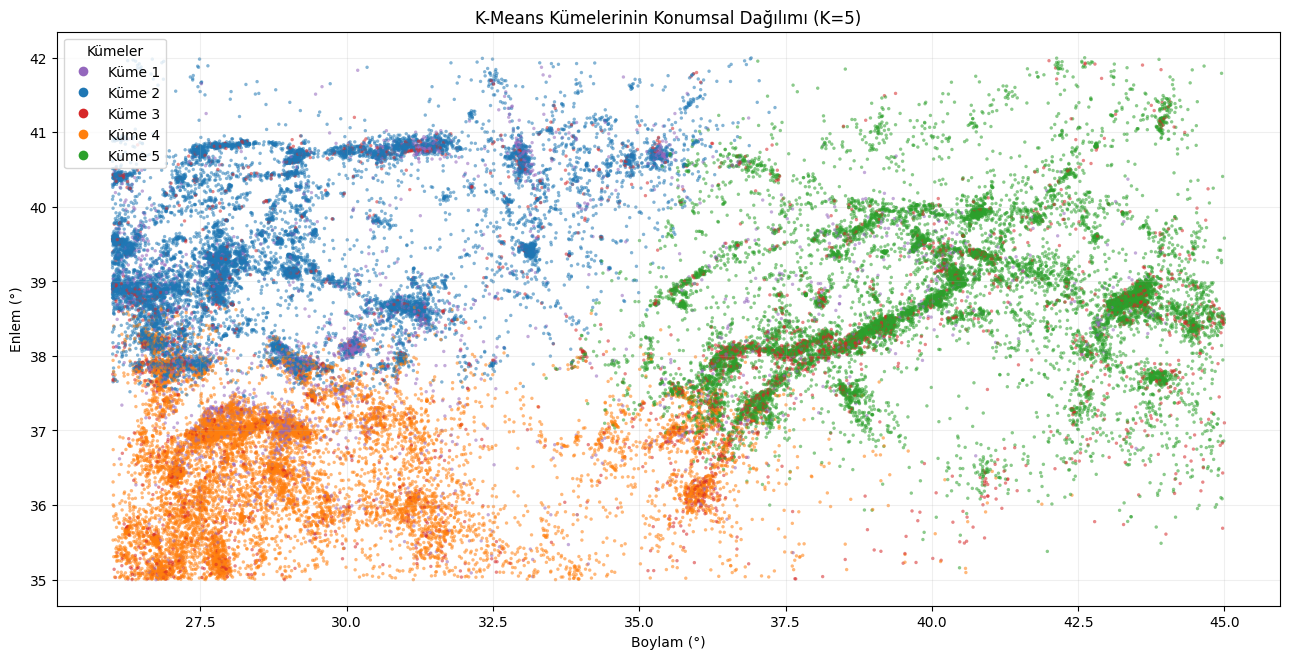

In [14]:
from matplotlib.lines import Line2D

# Aynı küme için sonraki grafiklerde de aynı rengi kullanacağız.
kume_renkleri = {
    1: "#9467bd",
    2: "#1f77b4",
    3: "#d62728",
    4: "#ff7f0e",
    5: "#2ca02c"
}

# Kümeleri sırayla çizmek son çizilen grubun diğerlerini
# örtmesine neden olabilir. Kayıt sırasını karıştırıyoruz.
# Bütün kayıtlar korunur; bu işlem örneklem küçültmez.
cizim_verisi = model_verisi.sample(frac=1, random_state=42)

fig, ax = plt.subplots(figsize=(13, 7))

ax.scatter(
    cizim_verisi["boylam"],
    cizim_verisi["enlem"],
    c=cizim_verisi["kume"].map(kume_renkleri),
    s=6,
    alpha=0.55,
    linewidths=0,
    rasterized=True
)

# Enlem-boylam görünümü için yaklaşık görsel oran düzeltmesi.
# Bu ayar modelin uzaklık hesabını değiştirmez.
ortalama_enlem = model_verisi["enlem"].mean()
ax.set_aspect(1 / np.cos(np.deg2rad(ortalama_enlem)))

lejant = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=kume_renkleri[k],
        markeredgecolor="none",
        markersize=7,
        label=f"Küme {k}"
    )
    for k in sorted(kume_renkleri)
]

ax.legend(handles=lejant, title="Kümeler", loc="upper left")
ax.set_title("K-Means Kümelerinin Konumsal Dağılımı (K=5)")
ax.set_xlabel("Boylam (°)")
ax.set_ylabel("Enlem (°)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Konumsal Dağılımın Yorumu

Küme 2 ağırlıklı olarak çalışma alanının kuzeybatısında,
Küme 4 güneybatısında, Küme 5 ise doğusunda yoğunlaşmaktadır.
Bu görünüm, konum özelliklerinin gruplamada etkili olduğunu
göstermektedir.

Ortalama büyüklüğü en yüksek olan Küme 3, farklı konumlarda
görülmektedir. Çok düşük kayıtlı derinliklerle ayrılan Küme 1
de tek bir coğrafi alanla sınırlı değildir.

Kümeler dört özellik kullanılarak oluşturulduğundan, konum
grafiğinde farklı kümelerin örtüşmesi beklenebilir. Bu grafik
tek başına dört boyutlu küme ayrımının kalitesini ölçmez.

Görülen renk geçişleri kesin bölge veya fay sınırları değildir.
Sonuçlar, seçilen özellikler ve K-Means yönteminin oluşturduğu
kayıt grupları olarak yorumlanmıştır.

## 12. Sıfır Derinlikli Kayıtlara Duyarlılık Analizi

### Amaç
Sıfır derinlikli kayıtların anlamı doğrulanamamıştır.
Bu kayıtlar ana analizde korunmuştur. Burada, dışlanmaları
durumunda kalan kayıtların küme yapısının ne kadar değiştiği
incelenecektir. Bu işlem sıfır değerlerinin hatalı olduğuna
dair bir kabul değildir.

### Yöntem
Derinliği sıfırdan büyük olan kayıtlarla yeni bir K-Means
modeli oluşturulacaktır. Küme sayısı 5 olarak korunacak;
ana analizde öğrenilen ölçekleme parametreleri kullanılacaktır.

Ana modelin ve yeni modelin etiketleri, yalnızca her iki
analizde de bulunan kayıtlar üzerinde karşılaştırılacaktır.

### Değerlendirme
Adjusted Rand Index (ARI), iki gruplamanın benzerliğini ölçer.
Küme numaralarının farklı olmasından etkilenmez.

- 1: İki gruplama aynıdır.
- 0 civarı: Uyum, rastlantısal gruplamalar için beklenen düzeydedir.
- Negatif değerler: Uyum bu düzeyin altındadır.

ARI doğruluk yüzdesi değildir. Bu deney, sabit K ve sabit
ölçekleme altında kayıt dışlamaya duyarlılığı değerlendirir;
en uygun küme sayısının değişip değişmediğini ölçmez.

In [15]:
from sklearn.metrics import adjusted_rand_score

# Ana tabloyu ve ana modeli değiştirmiyoruz.
pozitif_maske = model_verisi["derinlik_km"].gt(0).to_numpy()

# Mevcut ölçeklenmiş veriden ilgili satırları seç.
# Ölçekleyiciyi yeniden öğrenmiyoruz.
X_pozitif = X_olcekli[pozitif_maske]

# Ana modelin aynı kayıtlar için ürettiği etiketler.
ana_etiketler = son_model.labels_[pozitif_maske]

# Sıfır derinlikli kayıtlar olmadan yeni modeli oluştur.
pozitif_model = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=20,
    random_state=42
)
yeni_etiketler = pozitif_model.fit_predict(X_pozitif)

ari = adjusted_rand_score(ana_etiketler, yeni_etiketler)

print("Ana analizdeki kayıt sayısı:", len(model_verisi))
print("Dışlanan sıfır derinlikli kayıt:", (~pozitif_maske).sum())
print("Karşılaştırılan ortak kayıt:", len(X_pozitif))
print(f"\nİki gruplama arasındaki ARI: {ari:.4f}")

# Küme numaraları iki modelde aynı anlamı taşımayabilir.
# Çapraz tablo, grupların nasıl dağıldığını görmemizi sağlar.
gecis_tablosu = pd.crosstab(
    pd.Series(ana_etiketler + 1, name="Ana model kümesi"),
    pd.Series(yeni_etiketler + 1, name="Yeni model kümesi")
)

print("\nOrtak kayıtların iki modeldeki dağılımı:")
display(gecis_tablosu)

# Yeni kümelerin özgün birimlerle kısa profilleri.
pozitif_veri = model_verisi.loc[pozitif_maske].copy()
pozitif_veri["yeni_kume"] = yeni_etiketler + 1

yeni_profiller = pozitif_veri.groupby("yeni_kume").agg(
    kayit_sayisi=("deprem_kodu", "size"),
    enlem_ort=("enlem", "mean"),
    boylam_ort=("boylam", "mean"),
    derinlik_medyan_km=("derinlik_km", "median"),
    buyukluk_ort=("buyukluk", "mean")
)

print("\nSıfır derinlikler dışlandığında küme profilleri:")
display(yeni_profiller.round(3))

Ana analizdeki kayıt sayısı: 50000
Dışlanan sıfır derinlikli kayıt: 1756
Karşılaştırılan ortak kayıt: 48244

İki gruplama arasındaki ARI: 0.6959

Ortak kayıtların iki modeldeki dağılımı:


Yeni model kümesi,1,2,3,4,5
Ana model kümesi,,,,,
1,53,342,889,474,0
2,6,9,2986,12149,100
3,4367,0,62,11,121
4,49,75,7200,0,5047
5,60,13882,173,129,60



Sıfır derinlikler dışlandığında küme profilleri:


,kayit_sayisi,enlem_ort,boylam_ort,derinlik_medyan_km,buyukluk_ort
yeni_kume,,,,,
1,4535,38.196,34.672,6.1,4.274
2,14308,38.708,40.158,5.3,3.255
3,11310,37.086,28.798,6.9,3.245
4,12763,39.687,29.542,7.0,3.204
5,5328,36.516,29.827,21.9,3.357


### Duyarlılık Analizinin Bulguları

Sıfır derinlikli 1.756 kayıt dışlanmış ve kalan 48.244 kayıt
üzerinde K=5 modeli yeniden oluşturulmuştur. Ana model ile
yeni modelin ortak kayıtlar üzerindeki ARI değeri 0,6959'dur.

Yüksek büyüklüklerle ayrılan ana Küme 3 ve doğuda yoğunlaşan
ana Küme 5 büyük ölçüde korunmuştur. Buna karşılık, çok düşük
derinliklerle ayrılan ana Küme 1'in kalan üyeleri farklı
kümelere dağılmıştır. Ana Küme 4 de özellikle iki yeni grup
arasında bölünmüştür.

Bu sonuç, bazı profiller korunurken küme yapısının sıfır
derinlikli kayıtların dahil edilmesine duyarlı olduğunu
göstermektedir. Sıfır derinlikli kayıtların anlamının
doğrulanması, sonuçların yorumlanması açısından önemlidir.

Bu deney sıfır değerlerinin hatalı olduğunu veya dışlama
sonrasında elde edilen modelin daha doğru olduğunu kanıtlamaz.
Karşılaştırma sabit K=5 ve ana analizdeki ölçekleme altında
yapılmıştır. K-Means başlangıçlarının etkisi ayrıca
incelenmelidir.

## 13. Rastgele Başlangıçlara Karşı Kararlılık

K-Means farklı başlangıç merkezleriyle farklı çözümlere
ulaşabilir. Bu nedenle ana veri ve sıfır derinliklerin
dışlandığı veri üzerinde farklı rastgelelik tohumlarıyla
model tekrarları yapılacaktır.

Her tekrarda K=5, n_init=20 ve mevcut ölçekleme korunacaktır.
Her veri senaryosundaki sonuçlar, o senaryonun random_state=42
ile elde edilen referans modeliyle ARI kullanılarak
karşılaştırılacaktır.

Bu kontrol yalnızca başlangıçlara karşı kararlılığı ölçer.
Yüksek kararlılık, kümelerin bilimsel olarak doğru veya
doğal deprem bölgelerini temsil ettiğini kanıtlamaz.

In [16]:
kararlilik_sonuclari = []

# Her senaryoyu kendi referans modeliyle karşılaştırıyoruz.
senaryolar = [
    ("Tüm kayıtlar", X_olcekli, son_model),
    ("Sıfır derinlikler hariç", X_pozitif, pozitif_model)
]

for senaryo, X_senaryo, referans_model in senaryolar:
    for tohum in [0, 7, 21]:
        tekrar_model = KMeans(
            n_clusters=5,
            init="k-means++",
            n_init=20,
            random_state=tohum
        )

        tekrar_etiketler = tekrar_model.fit_predict(X_senaryo)

        ari_tekrar = adjusted_rand_score(
            referans_model.labels_,
            tekrar_etiketler
        )

        kararlilik_sonuclari.append({
            "senaryo": senaryo,
            "tohum": tohum,
            "referansa_gore_ARI": ari_tekrar,
            "inertia": tekrar_model.inertia_
        })

        print(
            f"{senaryo} | tohum={tohum} | "
            f"Referansla ARI={ari_tekrar:.4f}"
        )

kararlilik_tablosu = pd.DataFrame(kararlilik_sonuclari)
display(kararlilik_tablosu.round(4))

Tüm kayıtlar | tohum=0 | Referansla ARI=1.0000
Tüm kayıtlar | tohum=7 | Referansla ARI=1.0000
Tüm kayıtlar | tohum=21 | Referansla ARI=0.9999
Sıfır derinlikler hariç | tohum=0 | Referansla ARI=0.9942
Sıfır derinlikler hariç | tohum=7 | Referansla ARI=0.9962
Sıfır derinlikler hariç | tohum=21 | Referansla ARI=0.9957


,senaryo,tohum,referansa_gore_ARI,inertia
0,Tüm kayıtlar,0,1.0000,87808.5436
1,Tüm kayıtlar,7,1.0000,87808.5410
2,Tüm kayıtlar,21,0.9999,87808.5414
3,Sıfır derinlikler hariç,0,0.9942,76464.4592
4,Sıfır derinlikler hariç,7,0.9962,76464.4800
5,Sıfır derinlikler hariç,21,0.9957,76464.4713


### Kararlılık Analizinin Bulguları

Farklı rastgelelik tohumlarıyla yapılan tekrarlarda, ana model
ile karşılaştırılan ARI değerleri dört ondalık basamakta
0,9999–1,0000 aralığında bulunmuştur.

Sıfır derinliklerin dışlandığı senaryoda ise kendi referans
modeline göre ARI değerleri 0,9942–0,9962 aralığındadır.
Her iki senaryo da denenen başlangıçlarda yüksek kararlılık
göstermiştir.

Buna karşılık, sıfır derinliklerin dahil edildiği ve dışlandığı
modellerin ortak kayıtlar üzerindeki ARI değeri 0,6959'dur.
Kayıt dışlama sonucunda oluşan değişim, gözlenen başlangıç
değişkenliğinden belirgin biçimde büyüktür.

Dolayısıyla sıfır derinlikli kayıtların ele alınışı, küme
yapısını etkileyen bir analiz kararıdır. Bu sonuç, sıfır
değerlerinin anlamının doğrulanması gereğini desteklemektedir.

Yüksek başlangıç kararlılığı, kümelerin güçlü ayrıştığını
veya bilimsel olarak doğrulandığını göstermez. Ayrıca farklı
sayıda kayıt içeren senaryoların toplam inertia değerleri
doğrudan model üstünlüğü göstergesi olarak karşılaştırılmamıştır.

## 14. Küme Bazında Ayrışma ve Zayıf Atamaların İncelenmesi

Genel Silhouette skorunun yanında, kümelerin ayrı ayrı
ayrışma düzeyleri incelenecektir. Önceki değerlendirmede
kullanılan aynı 3.000 kayıtlık örneklem korunacaktır.

Pozitif ve yüksek Silhouette değerleri, kaydın kendi
kümesiyle daha uyumlu olduğunu gösterir. Sıfıra yakın
değerler kümeler arasında örtüşmeye işaret eder.

Negatif değer, kaydın başka bir kümeye olan ortalama
uzaklığının kendi kümesine olan ortalama uzaklığından
daha küçük olduğunu gösterir. Bu kayıtlar inceleme
adaylarıdır; kesin yanlış etiketlenmiş kayıtlar değildir.

K-Means merkezlere olan uzaklıkları, Silhouette ise
kümelerdeki kayıtlara olan ortalama uzaklıkları kullanır.
Bu nedenle negatif Silhouette değerleri, kod hatası
olmadan da görülebilir.

Hazır gerçek küme etiketleri bulunmadığından bu inceleme,
doğruluk veya sınıflandırma hata oranı hesaplamaz.
Sonuçlar kullanılan örneklem için geçerlidir.

In [17]:
from sklearn.metrics import silhouette_samples

# K seçimi sırasında kullanılan aynı örneklemi kullan.
ornek_ana_etiketler = son_model.labels_[ornek_indeksleri]

sil_degerleri = silhouette_samples(
    X_ornek,
    ornek_ana_etiketler
)

sil_inceleme = model_verisi.iloc[ornek_indeksleri].copy()
sil_inceleme["silhouette"] = sil_degerleri

# Her kümenin örneklem içindeki ayrışmasını özetle.
sil_ozet = sil_inceleme.groupby("kume").agg(
    ornek_kayit_sayisi=("silhouette", "size"),
    silhouette_ortalama=("silhouette", "mean"),
    silhouette_medyan=("silhouette", "median"),
    negatif_oran_yuzde=(
        "silhouette",
        lambda s: s.lt(0).mean() * 100
    )
)

print("Küme bazında Silhouette değerlendirmesi:")
display(sil_ozet.round(4))

print(f"\nÖrneklem genel ortalaması: {sil_degerleri.mean():.4f}")
print(
    "Örneklemde negatif Silhouette oranı: "
    f"%{(sil_degerleri < 0).mean() * 100:.2f}"
)

# En düşük skorlu kayıtları yalnızca incelemek için göster.
# Bu kayıtları otomatik olarak silmiyoruz.
print("\nÖrneklemde Silhouette değeri en düşük 10 kayıt:")
display(
    sil_inceleme.nsmallest(10, "silhouette")[
        [
            "deprem_kodu", "kume", "enlem", "boylam",
            "derinlik_km", "buyukluk", "silhouette"
        ]
    ].round(4)
)

Küme bazında Silhouette değerlendirmesi:


,ornek_kayit_sayisi,silhouette_ortalama,silhouette_medyan,negatif_oran_yuzde
kume,,,,
1,220,0.2427,0.2724,18.1818
2,904,0.3182,0.3284,0.0000
3,252,0.1346,0.1160,24.6032
4,741,0.2463,0.2599,6.4777
5,883,0.3452,0.3701,0.0000



Örneklem genel ortalaması: 0.2874
Örneklemde negatif Silhouette oranı: %5.00

Örneklemde Silhouette değeri en düşük 10 kayıt:


,deprem_kodu,kume,enlem,boylam,derinlik_km,buyukluk,silhouette
30164,20061025220015,3,39.0462,41.1320,8.2,3.9,-0.1642
8501,20190902154634,3,39.1765,40.2060,5.0,3.9,-0.1571
13827,20140704122853,3,38.4305,41.9865,6.9,3.9,-0.1549
22538,20091219013306,3,38.0822,38.1457,4.8,3.8,-0.1535
45972,19980407071221,1,38.1000,29.9500,3.0,3.1,-0.1505
48707,19951005211617,1,38.1600,30.2400,3.0,3.2,-0.1431
6291,20201102075705,3,38.1567,27.3273,4.7,3.8,-0.1404
24323,20090222193025,1,39.1342,29.0632,2.3,3.0,-0.1401
37883,20031101194005,3,38.4200,34.3400,10.0,3.7,-0.1397
1915,20230215173822,1,37.8430,36.5712,2.3,3.2,-0.1377


### Küme Bazında Ayrışma Bulguları

3.000 kayıtlık örneklemde genel Silhouette ortalaması 0,2874,
negatif Silhouette değerine sahip kayıtların oranı %5,00'dır.
Bu oran sınıflandırma hata oranı değildir.

Küme 5 (0,3452) ve Küme 2 (0,3182), ortalama Silhouette
bakımından diğer kümelerden daha yüksek ayrışma göstermiştir.
Örneklemde bu iki kümede negatif Silhouette görülmemiştir.

Küme 3, 0,1346 ortalama Silhouette ve %24,60 negatif değer
oranıyla en fazla örtüşme gösteren gruptur. Bu kümenin
ortalama büyüklüğünün yüksek olması, tüm üyelerinin diğer
gruplardan belirgin biçimde ayrıldığı anlamına gelmemektedir.

En düşük Silhouette değerine sahip 10 kayıt içindeki Küme 3
üyelerinin büyüklükleri 3,7–3,9 aralığındadır. Bu değerler
kümenin ortalama büyüklüğünün altındadır. Diğer özelliklerdeki
benzerlikler de bu kayıtların zayıf ayrışmasına katkıda bulunuyor
olabilir.

Küme 1'deki %18,18 negatif değer oranı, düşük kayıtlı derinlikle
ayrılan bu grubun da örtüşme içerdiğini göstermektedir.
Bu bulgu, sıfır derinlik duyarlılık analiziyle birlikte
değerlendirilmelidir.

Düşük skorlu kayıtlar otomatik olarak silinmemiştir. Gerçek
küme etiketleri bulunmadığından bunlar kesin yanlış atamalar
olarak değerlendirilmemiştir. Bulgular kullanılan örneklemle
sınırlıdır.

## 15. Sonuç, Sınırlılıklar ve İyileştirme Önerileri

### Sonuç
Bu çalışmada Türkiye ve çevresine ait 50.000 deprem kaydı;
enlem, boylam, logaritmik derinlik ve dosyadaki xM büyüklük
değeri kullanılarak K-Means ile kümelenmiştir.

2–10 arasındaki küme sayıları karşılaştırılmış; en yüksek
Silhouette (0,2874) ve en düşük Davies–Bouldin (1,1002)
değerlerini veren K=5 seçilmiştir.

Kümeler arasında konum, kayıtlı derinlik ve büyüklük
bakımından farklı profiller görülmüştür. Bununla birlikte,
özellikle yüksek büyüklüklerle ayrılan Küme 3'te örtüşme
bulunmaktadır.

Farklı başlangıçlarla elde edilen sonuçlar oldukça
kararlıdır. Ancak sıfır derinlikli kayıtların dışlanması,
ortak kayıtlarda ARI=0,6959 ile daha belirgin bir değişim
oluşturmuştur. Dolayısıyla başlangıç kararlılığı yüksek
olsa da veri ön işleme kararları sonuçları etkilemektedir.

### Sınırlılıklar
- Sonuçlar kullanılan katalog kesiti için geçerlidir.
  1994 ve 2023 yılları kısmi dönemleri kapsamaktadır.
- Veride gözlenen en küçük büyüklük 3,0'dır. Bu veri,
  daha küçük depremlerin dağılımını değerlendirmeye uygun değildir.
- Sıfır derinlik değerlerinin ve kayıt türü kodlarının
  anlamları doğrulanamamıştır.
- xM değerlerinin tek ve homojen bir büyüklük ölçeğini
  temsil ettiği varsayılmamıştır.
- Standartlaştırılmış enlem-boylam uzaklıkları,
  kilometre cinsinden coğrafi uzaklık değildir.
- K-Means'in kompakt küme yapısı tercihi, uzamış veya
  düzensiz grupları temsil etmesini sınırlayabilir.
- Silhouette değerlendirmesi 3.000 kayıtlık örnekleme
  dayanmaktadır.
- Gerçek küme etiketleri ve bağımsız uzman doğrulaması yoktur.
- Zamansal bağımlılık ve artçı deprem dizilerinin etkisi
  ayrıca incelenmemiştir.

### İyileştirme Önerileri
Öncelikle katalog alanlarının tanımları ve sıfır derinlik
değerlerinin anlamı kaynak üzerinden doğrulanmalıdır.
Farklı özellik ağırlıkları, derinlik dönüşümleri ve uygun
coğrafi uzaklık yaklaşımları karşılaştırılabilir.

Aynı özellikler ve tutarlı değerlendirme koşulları altında
alternatif kümeleme yöntemleri denenebilir. Farklı zaman
dilimleri ve Silhouette örneklemleriyle sonuçların
duyarlılığı ayrıca incelenebilir.

### Kullanım Kapsamı
Çalışma, geçmiş deprem kayıtlarını özetleyen keşifsel bir
analizdir. Gelecekteki depremleri tahmin etmez; deprem
tehlikesi veya risk haritası üretmez.